<a href="https://colab.research.google.com/github/Yireh111/MachineLearning/blob/main/Unidad%20III/Proyecto_Integrador_U3_Titanic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto Integrador Unidad 3: Análisis de Modelos de Clasificación en el Titanic

**Objetivo:** Analizar y comparar el desempeño de cinco algoritmos de Machine Learning supervisado (KNN, Regresión Logística, Árbol de Decisión, Random Forest y SVM) para predecir la supervivencia de pasajeros del Titanic.

**Dataset:** Titanic de Kaggle.

**Variable objetivo:** `Survived` (0 = No sobrevivió, 1 = Sobrevivió).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

sns.set_theme(style="whitegrid")

In [ ]:
df = pd.read_csv("train.csv")

print("Dimensiones del dataset:", df.shape)
display(df.head())

Dimensiones del dataset: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
print("Información general:")
df.info()

print("\nValores faltantes por columna:")
display(df.isnull().sum())

print("\nDistribución de supervivencia:")
display(df["Survived"].value_counts())

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Valores faltantes por columna:


,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0



Distribución de supervivencia:


,count
Survived,
0,549
1,342


## 5. Análisis exploratorio de datos (EDA)

### 5.1. Supervivencia por sexo

Se analiza la relación entre el sexo de los pasajeros y su supervivencia para identificar posibles diferencias entre hombres y mujeres.

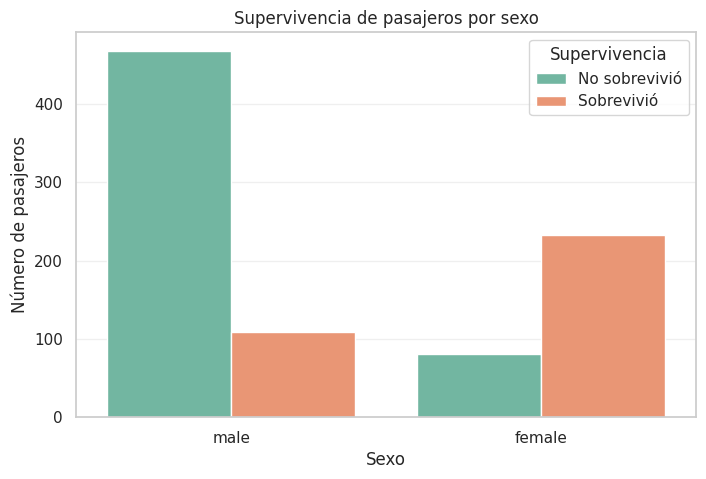

Porcentaje de supervivencia por sexo:


,Survived
Sex,
female,74.20
male,18.89


In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Sex",
    hue="Survived",
    palette="Set2"
)

plt.title("Supervivencia de pasajeros por sexo")
plt.xlabel("Sexo")
plt.ylabel("Número de pasajeros")
plt.legend(title="Supervivencia", labels=["No sobrevivió", "Sobrevivió"])
plt.grid(axis="y", alpha=0.3)
plt.show()

print("Porcentaje de supervivencia por sexo:")
display(df.groupby("Sex")["Survived"].mean().mul(100).round(2))

### Interpretación

Los resultados muestran una diferencia considerable en la supervivencia según el sexo de los pasajeros.

El **74.20% de las mujeres sobrevivió**, mientras que solamente el **18.89% de los hombres logró sobrevivir**.

Esto indica que el sexo fue una característica importante asociada con la supervivencia durante el desastre del Titanic. Las mujeres presentaron una probabilidad de supervivencia observada considerablemente mayor que los hombres.

### 5.2. Supervivencia por clase

Se compara la supervivencia de los pasajeros según la clase en la que viajaban: primera, segunda o tercera.

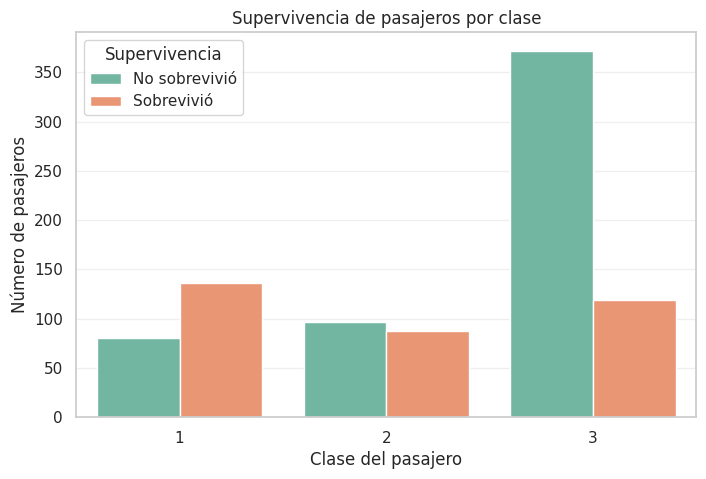

Porcentaje de supervivencia por clase:


,Survived
Pclass,
1,62.96
2,47.28
3,24.24


In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Pclass",
    hue="Survived",
    palette="Set2"
)

plt.title("Supervivencia de pasajeros por clase")
plt.xlabel("Clase del pasajero")
plt.ylabel("Número de pasajeros")
plt.legend(title="Supervivencia", labels=["No sobrevivió", "Sobrevivió"])
plt.grid(axis="y", alpha=0.3)
plt.show()

print("Porcentaje de supervivencia por clase:")
display(df.groupby("Pclass")["Survived"].mean().mul(100).round(2))

### Interpretación

Los resultados muestran que la clase del pasajero estuvo relacionada con sus posibilidades de supervivencia.

Los pasajeros de **primera clase registraron un 62.96% de supervivencia**, los de **segunda clase un 47.28%** y los de **tercera clase solamente un 24.24%**.

Esto muestra que los pasajeros de primera clase tuvieron una mayor proporción de supervivientes, mientras que los de tercera clase registraron la menor.

Por lo tanto, la clase del pasajero representa una variable relevante para los modelos de clasificación.

### 5.3. Supervivencia por edad

Se analiza la distribución de las edades de los pasajeros según su supervivencia, con el propósito de identificar posibles diferencias entre los grupos.

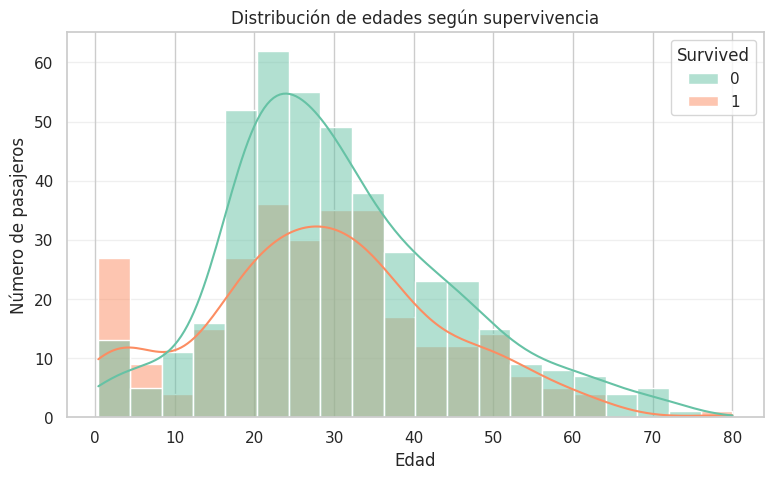

Estadísticas de edad según supervivencia:


,count,mean,std,min,25%,50%,75%,max
Survived,,,,,,,,
0,424.0,30.63,14.17,1.00,21.0,28.0,39.0,74.0
1,290.0,28.34,14.95,0.42,19.0,28.0,36.0,80.0


In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Age",
    hue="Survived",
    bins=20,
    kde=True,
    palette="Set2",
    alpha=0.5
)

plt.title("Distribución de edades según supervivencia")
plt.xlabel("Edad")
plt.ylabel("Número de pasajeros")
plt.grid(axis="y", alpha=0.3)
plt.show()

print("Estadísticas de edad según supervivencia:")
display(df.groupby("Survived")["Age"].describe().round(2))

### Interpretación

La distribución de edades muestra que la mayor concentración de pasajeros se encuentra aproximadamente entre los **20 y 40 años**, tanto entre sobrevivientes como entre quienes no sobrevivieron.

La edad promedio de los pasajeros que **no sobrevivieron fue de 30.63 años**, mientras que la de quienes **sí sobrevivieron fue de 28.34 años**.

También se observa una presencia considerable de niños pequeños entre los sobrevivientes.

Aunque existen diferencias entre ambos grupos, sus distribuciones presentan un solapamiento importante, por lo que la edad por sí sola no permite determinar con precisión la supervivencia de un pasajero.

Además, este análisis considera únicamente los registros con edad conocida, ya que existen **177 valores faltantes** en esta variable.

## 6. Preparación y limpieza de datos

Se seleccionan las variables relacionadas con la supervivencia de los pasajeros: clase, sexo, edad, familiares a bordo, tarifa y puerto de embarque.

La columna `Cabin` se excluye debido a su elevada cantidad de valores faltantes. Para `Age` se utilizará la mediana y para `Embarked` la categoría más frecuente.

La imputación y el escalamiento se realizarán utilizando los datos de entrenamiento, evitando que la información del conjunto de prueba influya en el aprendizaje del modelo.

In [ ]:
variables = [
    "Pclass", "Sex", "Age", "SibSp",
    "Parch", "Fare", "Embarked"
]

X = df[variables]
y = df["Survived"]

print("Variables predictoras:")
print(X.columns.tolist())

print("\nVariable objetivo:")
print(y.name)

print("\nDimensiones:")
print("X:", X.shape)
print("y:", y.shape)

Variables predictoras:
['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']

Variable objetivo:
Survived

Dimensiones:
X: (891, 7)
y: (891,)


### 6.2. División del conjunto de datos

El conjunto de datos se divide en un 70% para entrenamiento y un 30% para prueba. Se utiliza `stratify=y` para mantener aproximadamente la misma proporción de sobrevivientes y no sobrevivientes en ambos conjuntos.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Registros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))

print("\nDistribución de clases en entrenamiento:")
display(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nDistribución de clases en prueba:")
display(y_test.value_counts(normalize=True).mul(100).round(2))

Registros de entrenamiento: 623
Registros de prueba: 268

Distribución de clases en entrenamiento:


,proportion
Survived,
0,61.64
1,38.36



Distribución de clases en prueba:


,proportion
Survived,
0,61.57
1,38.43


In [ ]:
variables_numericas = [
    "Pclass", "Age", "SibSp", "Parch", "Fare"
]

variables_categoricas = ["Embarked"]

# Sex: masculino = 0, femenino = 1
X_train = X_train.copy()
X_test = X_test.copy()

X_train["Sex"] = X_train["Sex"].map({"male": 0, "female": 1})
X_test["Sex"] = X_test["Sex"].map({"male": 0, "female": 1})

# Limpieza y escalamiento para modelos sensibles a distancias
pipeline_numerico_escalado = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalamiento", StandardScaler())
])

# Limpieza sin escalamiento para árboles
pipeline_numerico_arbol = Pipeline([
    ("imputacion", SimpleImputer(strategy="median"))
])

# Codificación del puerto de embarque
pipeline_categorico = Pipeline([
    ("imputacion", SimpleImputer(strategy="most_frequent")),
    ("codificacion", OneHotEncoder(handle_unknown="ignore"))
])

preprocesador_escalado = ColumnTransformer([
    ("numericas", pipeline_numerico_escalado, variables_numericas),
    ("sexo", "passthrough", ["Sex"]),
    ("categoricas", pipeline_categorico, variables_categoricas)
])

preprocesador_arbol = ColumnTransformer([
    ("numericas", pipeline_numerico_arbol, variables_numericas),
    ("sexo", "passthrough", ["Sex"]),
    ("categoricas", pipeline_categorico, variables_categoricas)
])

print("Preprocesadores configurados correctamente.")

Preprocesadores configurados correctamente.


### 6.4. Justificación del escalamiento

**KNN:** requiere escalamiento porque utiliza distancias entre observaciones. Si las variables tienen escalas muy diferentes, aquellas con valores numéricos mayores pueden dominar el cálculo.

**SVM:** el escalamiento permite que las variables contribuyan de manera más equilibrada al cálculo de la frontera de decisión, especialmente cuando se utilizan kernels basados en distancias.

**Árboles de decisión y Random Forest:** generalmente no requieren escalamiento porque realizan divisiones mediante condiciones sobre los valores de las variables, sin depender de distancias entre observaciones.

Para esta práctica se utilizará `StandardScaler` en los modelos que requieren escalamiento y se conservarán los valores originales para los modelos basados en árboles.

## 7. Entrenamiento y evaluación de modelos

### 7.1. KNN (K-Nearest Neighbors)

KNN es un algoritmo de clasificación supervisada que determina la clase de una observación a partir de las clases de sus vecinos más cercanos.

En esta práctica se utiliza para predecir si un pasajero sobrevivió o no al Titanic, considerando sus características personales y las condiciones de su viaje.

Se utiliza `StandardScaler` para evitar que las diferencias de escala entre las variables afecten el cálculo de distancias.

In [ ]:
# Crear el modelo KNN con preprocesamiento
modelo_knn = Pipeline([
    ("preprocesamiento", preprocesador_escalado),
    ("clasificador", KNeighborsClassifier(n_neighbors=5))
])

# Entrenar el modelo
modelo_knn.fit(X_train, y_train)

# Realizar predicciones
y_pred_knn = modelo_knn.predict(X_test)

# Calcular métricas
accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn)
recall_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)
auc_knn = roc_auc_score(
    y_test,
    modelo_knn.predict_proba(X_test)[:, 1]
)

print("RESULTADOS DEL MODELO KNN")
print(f"Accuracy: {accuracy_knn:.4f}")
print(f"Precision: {precision_knn:.4f}")
print(f"Recall: {recall_knn:.4f}")
print(f"F1-score: {f1_knn:.4f}")
print(f"AUC: {auc_knn:.4f}")

print("\nReporte de clasificación:")
print(classification_report(
    y_test,
    y_pred_knn,
    target_names=["No sobrevivió", "Sobrevivió"]
))

RESULTADOS DEL MODELO KNN
Accuracy: 0.7724
Precision: 0.7143
Recall: 0.6796
F1-score: 0.6965
AUC: 0.7974

Reporte de clasificación:
               precision    recall  f1-score   support

No sobrevivió       0.81      0.83      0.82       165
   Sobrevivió       0.71      0.68      0.70       103

     accuracy                           0.77       268
    macro avg       0.76      0.75      0.76       268
 weighted avg       0.77      0.77      0.77       268



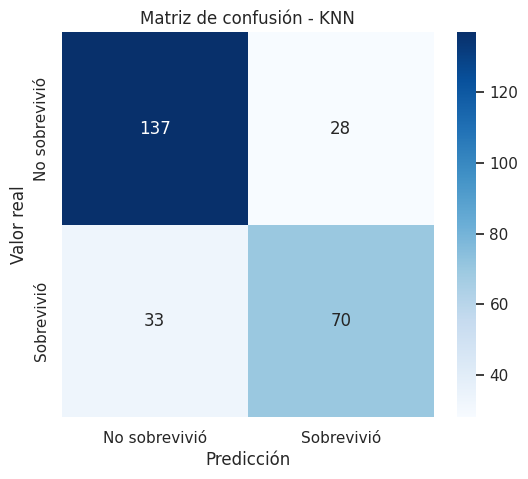

In [ ]:
matriz_knn = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(6, 5))

sns.heatmap(
    matriz_knn,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No sobrevivió", "Sobrevivió"],
    yticklabels=["No sobrevivió", "Sobrevivió"]
)

plt.title("Matriz de confusión - KNN")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.show()

### Interpretación de resultados de KNN

El modelo KNN obtuvo una exactitud (Accuracy) del **77.24%**, lo que significa que clasificó correctamente a 207 de los 268 pasajeros del conjunto de prueba.

El Recall de los pasajeros que no sobrevivieron fue del **83.03%**, mientras que para los sobrevivientes fue del **67.96%**. Esto indica que el modelo identifica mejor a los pasajeros que no sobrevivieron.

La matriz de confusión muestra **137 verdaderos negativos, 70 verdaderos positivos, 28 falsos positivos y 33 falsos negativos**, considerando la supervivencia como clase positiva.

El F1-score de **69.65%** para los sobrevivientes refleja un equilibrio moderado entre Precision y Recall. Por su parte, el AUC de **79.74%** indica una capacidad de discriminación razonable entre ambas clases.

**Ventajas:** KNN es un algoritmo sencillo y permite clasificar pasajeros a partir de la similitud entre sus características.

**Limitaciones:** Es sensible al escalamiento, a la selección de variables y al número de vecinos. Además, presenta dificultades para identificar a todos los sobrevivientes.

**Posibles mejoras:** Probar distintos valores de `n_neighbors`, ajustar las métricas de distancia y optimizar los hiperparámetros mediante validación cruzada.

### 7.2. Regresión logística

La regresión logística es un algoritmo de clasificación supervisada que estima la probabilidad de pertenecer a una clase.

En este proyecto se utiliza para predecir la probabilidad de supervivencia de los pasajeros a partir de sus características.

Se aplica el mismo conjunto de entrenamiento y prueba utilizado en KNN, permitiendo comparar ambos modelos bajo las mismas condiciones.

In [ ]:
# Crear modelo de regresión logística
modelo_logistico = Pipeline([
    ("preprocesamiento", preprocesador_escalado),
    ("clasificador", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Entrenar modelo
modelo_logistico.fit(X_train, y_train)

# Realizar predicciones
y_pred_logistico = modelo_logistico.predict(X_test)

# Calcular métricas
accuracy_logistico = accuracy_score(y_test, y_pred_logistico)
precision_logistico = precision_score(y_test, y_pred_logistico)
recall_logistico = recall_score(y_test, y_pred_logistico)
f1_logistico = f1_score(y_test, y_pred_logistico)

auc_logistico = roc_auc_score(
    y_test,
    modelo_logistico.predict_proba(X_test)[:, 1]
)

print("RESULTADOS DE REGRESIÓN LOGÍSTICA")
print(f"Accuracy: {accuracy_logistico:.4f}")
print(f"Precision: {precision_logistico:.4f}")
print(f"Recall: {recall_logistico:.4f}")
print(f"F1-score: {f1_logistico:.4f}")
print(f"AUC: {auc_logistico:.4f}")

print("\nReporte de clasificación:")
print(classification_report(
    y_test,
    y_pred_logistico,
    target_names=["No sobrevivió", "Sobrevivió"]
))

RESULTADOS DE REGRESIÓN LOGÍSTICA
Accuracy: 0.8022
Precision: 0.7500
Recall: 0.7282
F1-score: 0.7389
AUC: 0.8496

Reporte de clasificación:
               precision    recall  f1-score   support

No sobrevivió       0.83      0.85      0.84       165
   Sobrevivió       0.75      0.73      0.74       103

     accuracy                           0.80       268
    macro avg       0.79      0.79      0.79       268
 weighted avg       0.80      0.80      0.80       268



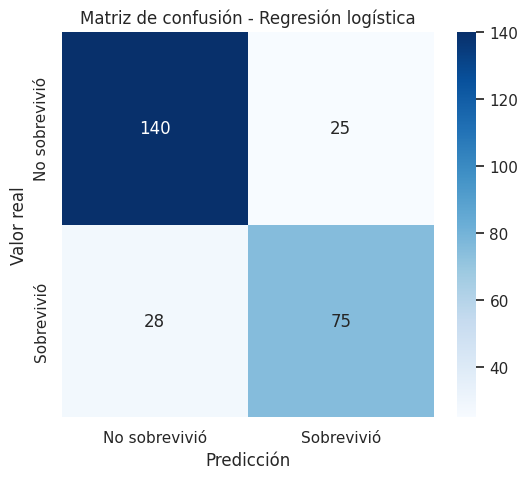

In [ ]:
matriz_logistico = confusion_matrix(y_test, y_pred_logistico)

plt.figure(figsize=(6, 5))

sns.heatmap(
    matriz_logistico,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No sobrevivió", "Sobrevivió"],
    yticklabels=["No sobrevivió", "Sobrevivió"]
)

plt.title("Matriz de confusión - Regresión logística")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.show()

### Interpretación de resultados de regresión logística

El modelo de regresión logística obtuvo una exactitud (Accuracy) del **80.22%**, clasificando correctamente a 215 de los 268 pasajeros del conjunto de prueba.

El Recall de los pasajeros que no sobrevivieron fue del **84.85%**, mientras que el Recall de los sobrevivientes fue del **72.82%**. Esto indica que el modelo identifica mejor a los pasajeros que no sobrevivieron.

La matriz de confusión presenta **140 verdaderos negativos, 75 verdaderos positivos, 25 falsos positivos y 28 falsos negativos**.

El F1-score de **73.89%** y el AUC de **84.96%** muestran una capacidad de clasificación y discriminación favorable.

En comparación con KNN, la regresión logística obtuvo mejores resultados en Accuracy, Recall, F1-score y AUC.

**Ventajas:** Es un modelo relativamente sencillo, eficiente e interpretable, que permite estimar probabilidades de supervivencia.

**Limitaciones:** Supone una relación lineal entre las variables predictoras y el logaritmo de las probabilidades relativas (*log-odds*), por lo que puede tener dificultades para representar relaciones complejas.

**Posibles mejoras:** Ajustar la regularización, incorporar nuevas características y optimizar los hiperparámetros mediante validación cruzada.

### 7.3. Árbol de decisión

El árbol de decisión es un algoritmo de clasificación supervisada que utiliza reglas basadas en las características de los pasajeros para determinar si sobrevivieron o no.

A diferencia de KNN y regresión logística, no requiere escalamiento de variables y puede representar relaciones no lineales.

Para esta práctica se utilizará un árbol con profundidad máxima de 4, con el propósito de controlar su complejidad y facilitar su interpretación.

In [ ]:
# Crear modelo de árbol de decisión
modelo_arbol = Pipeline([
    ("preprocesamiento", preprocesador_arbol),
    ("clasificador", DecisionTreeClassifier(
        max_depth=4,
        random_state=42
    ))
])

# Entrenar modelo
modelo_arbol.fit(X_train, y_train)

# Realizar predicciones
y_pred_arbol = modelo_arbol.predict(X_test)

# Calcular métricas
accuracy_arbol = accuracy_score(y_test, y_pred_arbol)
precision_arbol = precision_score(y_test, y_pred_arbol)
recall_arbol = recall_score(y_test, y_pred_arbol)
f1_arbol = f1_score(y_test, y_pred_arbol)

auc_arbol = roc_auc_score(
    y_test,
    modelo_arbol.predict_proba(X_test)[:, 1]
)

print("RESULTADOS DEL ÁRBOL DE DECISIÓN")
print(f"Accuracy: {accuracy_arbol:.4f}")
print(f"Precision: {precision_arbol:.4f}")
print(f"Recall: {recall_arbol:.4f}")
print(f"F1-score: {f1_arbol:.4f}")
print(f"AUC: {auc_arbol:.4f}")

print("\nReporte de clasificación:")
print(classification_report(
    y_test,
    y_pred_arbol,
    target_names=["No sobrevivió", "Sobrevivió"]
))

RESULTADOS DEL ÁRBOL DE DECISIÓN
Accuracy: 0.7948
Precision: 0.8636
Recall: 0.5534
F1-score: 0.6746
AUC: 0.8244

Reporte de clasificación:
               precision    recall  f1-score   support

No sobrevivió       0.77      0.95      0.85       165
   Sobrevivió       0.86      0.55      0.67       103

     accuracy                           0.79       268
    macro avg       0.82      0.75      0.76       268
 weighted avg       0.81      0.79      0.78       268



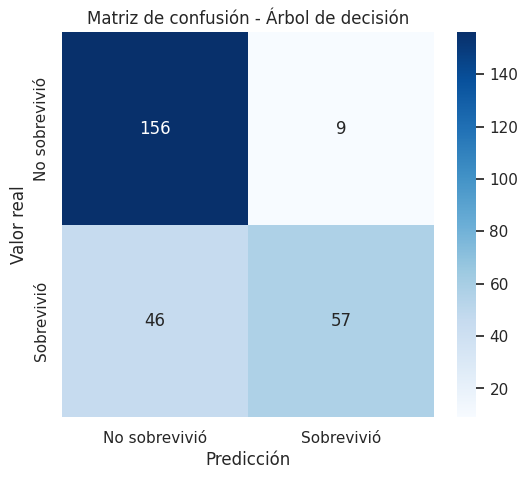

In [ ]:
matriz_arbol = confusion_matrix(y_test, y_pred_arbol)

plt.figure(figsize=(6, 5))

sns.heatmap(
    matriz_arbol,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No sobrevivió", "Sobrevivió"],
    yticklabels=["No sobrevivió", "Sobrevivió"]
)

plt.title("Matriz de confusión - Árbol de decisión")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.show()

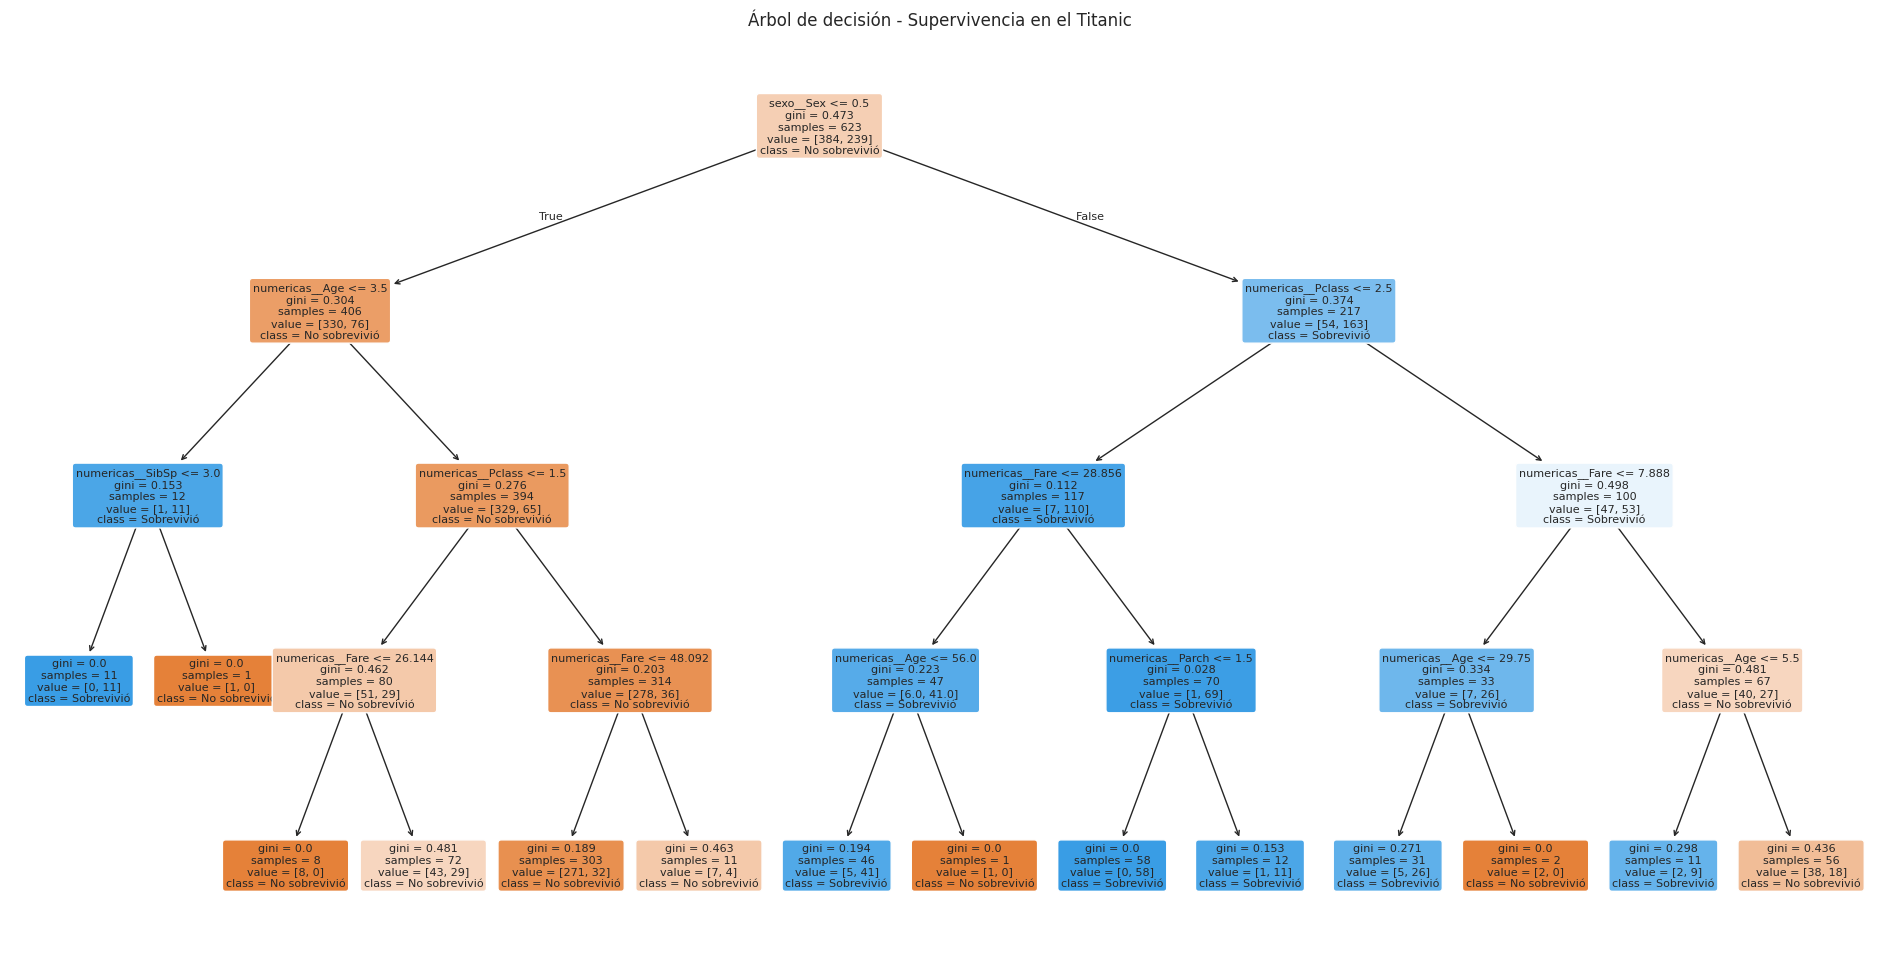

In [ ]:
plt.figure(figsize=(24, 12))

plot_tree(
    modelo_arbol.named_steps["clasificador"],
    feature_names=modelo_arbol.named_steps[
        "preprocesamiento"
    ].get_feature_names_out(),
    class_names=["No sobrevivió", "Sobrevivió"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Árbol de decisión - Supervivencia en el Titanic")
plt.show()

### Interpretación de resultados del árbol de decisión

El árbol de decisión obtuvo una exactitud (Accuracy) del **79.48%**, clasificando correctamente a 213 de los 268 pasajeros del conjunto de prueba.

El Recall de los pasajeros que no sobrevivieron fue del **94.55%**, mientras que el Recall de los sobrevivientes fue del **55.34%**. Esto indica que el modelo identifica con mayor facilidad a quienes no sobrevivieron, pero presenta dificultades para reconocer a todos los sobrevivientes.

La matriz de confusión muestra **156 verdaderos negativos, 57 verdaderos positivos, 9 falsos positivos y 46 falsos negativos**.

El F1-score de **67.46%** y el AUC de **82.44%** muestran un desempeño razonable, aunque inferior al de regresión logística en estas métricas.

**Interpretación del árbol:** La primera división utiliza la variable `Sex`, lo que indica su importancia para clasificar a los pasajeros. Posteriormente, el modelo considera variables como `Age`, `Pclass`, `Fare`, `SibSp` y `Parch` para establecer reglas más específicas.

**Ventajas:** Permite visualizar las decisiones del modelo, interpretar sus reglas y representar relaciones no lineales.

**Limitaciones:** Puede presentar sobreajuste y es sensible a los cambios en los datos. En esta configuración, presenta un Recall bajo para los sobrevivientes.

**Posibles mejoras:** Ajustar `max_depth`, `min_samples_split` y `min_samples_leaf`, además de utilizar validación cruzada para encontrar una configuración más equilibrada.

### 7.4. Random Forest

Random Forest es un algoritmo de clasificación supervisada que combina múltiples árboles de decisión para generar predicciones.

A diferencia de un árbol individual, utiliza un conjunto de árboles para mejorar la estabilidad del modelo y reducir el riesgo de sobreajuste.

En esta práctica se utilizarán 100 árboles de decisión y el mismo conjunto de entrenamiento y prueba empleado en los modelos anteriores.

In [ ]:
# Crear modelo Random Forest
modelo_rf = Pipeline([
    ("preprocesamiento", preprocesador_arbol),
    ("clasificador", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

# Entrenar modelo
modelo_rf.fit(X_train, y_train)

# Realizar predicciones
y_pred_rf = modelo_rf.predict(X_test)

# Calcular métricas
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

auc_rf = roc_auc_score(
    y_test,
    modelo_rf.predict_proba(X_test)[:, 1]
)

print("RESULTADOS DE RANDOM FOREST")
print(f"Accuracy: {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall: {recall_rf:.4f}")
print(f"F1-score: {f1_rf:.4f}")
print(f"AUC: {auc_rf:.4f}")

print("\nReporte de clasificación:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["No sobrevivió", "Sobrevivió"]
))

RESULTADOS DE RANDOM FOREST
Accuracy: 0.7948
Precision: 0.7553
Recall: 0.6893
F1-score: 0.7208
AUC: 0.8405

Reporte de clasificación:
               precision    recall  f1-score   support

No sobrevivió       0.82      0.86      0.84       165
   Sobrevivió       0.76      0.69      0.72       103

     accuracy                           0.79       268
    macro avg       0.79      0.77      0.78       268
 weighted avg       0.79      0.79      0.79       268



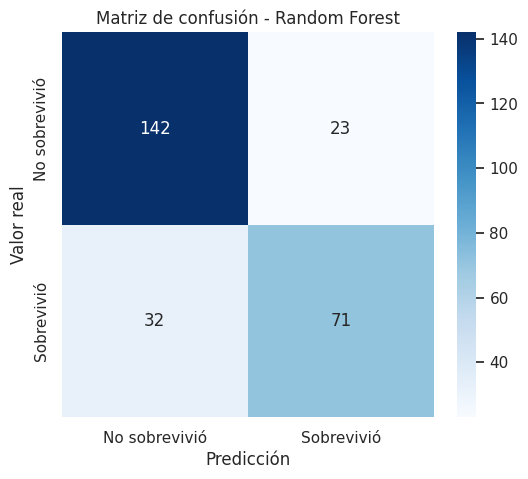

In [ ]:
matriz_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 5))

sns.heatmap(
    matriz_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No sobrevivió", "Sobrevivió"],
    yticklabels=["No sobrevivió", "Sobrevivió"]
)

plt.title("Matriz de confusión - Random Forest")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.show()

### Interpretación de resultados de Random Forest

El modelo Random Forest obtuvo una exactitud (Accuracy) del **79.48%**, clasificando correctamente a 213 de los 268 pasajeros del conjunto de prueba.

El Recall de los pasajeros que no sobrevivieron fue del **86.06%**, mientras que para los sobrevivientes fue del **68.93%**. Esto indica que el modelo identifica mejor a los pasajeros que no sobrevivieron.

La matriz de confusión presenta **142 verdaderos negativos, 71 verdaderos positivos, 23 falsos positivos y 32 falsos negativos**.

El F1-score de **72.08%** y el AUC de **84.05%** muestran una capacidad de clasificación favorable.

En comparación con el árbol de decisión individual, Random Forest obtuvo la misma exactitud, pero mejoró el Recall y el F1-score de los sobrevivientes. Sin embargo, la regresión logística continúa presentando mejores resultados generales.

**Ventajas:** Combina múltiples árboles de decisión, puede representar relaciones no lineales y suele ofrecer mayor estabilidad que un árbol individual.

**Limitaciones:** Su interpretación es más compleja que la de un solo árbol y requiere mayores recursos computacionales.

**Posibles mejoras:** Ajustar `n_estimators`, `max_depth`, `min_samples_split` y `min_samples_leaf`, utilizando validación cruzada para seleccionar los mejores parámetros.

### 7.5. SVM (Support Vector Machine)

SVM es un algoritmo de clasificación supervisada que busca encontrar una frontera de decisión que permita separar las diferentes clases.

En esta práctica se utiliza para predecir la supervivencia de los pasajeros del Titanic mediante un kernel RBF, que permite representar relaciones no lineales.

Se aplica escalamiento mediante `StandardScaler`, ya que SVM es sensible a las diferencias de escala entre las variables predictoras.

In [ ]:
# Crear modelo SVM
modelo_svm = Pipeline([
    ("preprocesamiento", preprocesador_escalado),
    ("clasificador", SVC(
        kernel="rbf",
        C=1.0,
        probability=True,
        random_state=42
    ))
])

# Entrenar modelo
modelo_svm.fit(X_train, y_train)

# Realizar predicciones
y_pred_svm = modelo_svm.predict(X_test)

# Calcular métricas
accuracy_svm = accuracy_score(y_test, y_pred_svm)
precision_svm = precision_score(y_test, y_pred_svm)
recall_svm = recall_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm)

auc_svm = roc_auc_score(
    y_test,
    modelo_svm.predict_proba(X_test)[:, 1]
)

print("RESULTADOS DEL MODELO SVM")
print(f"Accuracy: {accuracy_svm:.4f}")
print(f"Precision: {precision_svm:.4f}")
print(f"Recall: {recall_svm:.4f}")
print(f"F1-score: {f1_svm:.4f}")
print(f"AUC: {auc_svm:.4f}")

print("\nReporte de clasificación:")
print(classification_report(
    y_test,
    y_pred_svm,
    target_names=["No sobrevivió", "Sobrevivió"]
))

RESULTADOS DEL MODELO SVM
Accuracy: 0.8097
Precision: 0.7766
Recall: 0.7087
F1-score: 0.7411
AUC: 0.8449

Reporte de clasificación:
               precision    recall  f1-score   support

No sobrevivió       0.83      0.87      0.85       165
   Sobrevivió       0.78      0.71      0.74       103

     accuracy                           0.81       268
    macro avg       0.80      0.79      0.80       268
 weighted avg       0.81      0.81      0.81       268



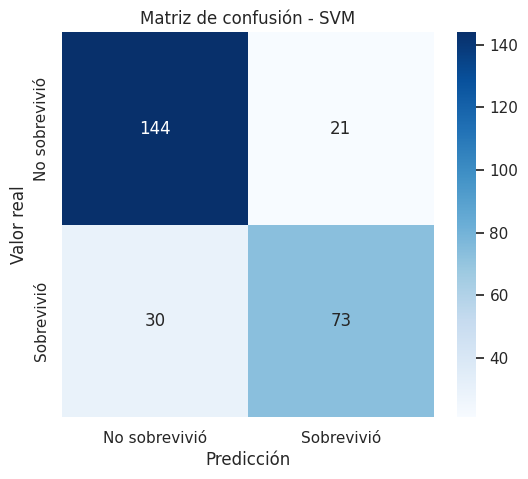

In [ ]:
matriz_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(6, 5))

sns.heatmap(
    matriz_svm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No sobrevivió", "Sobrevivió"],
    yticklabels=["No sobrevivió", "Sobrevivió"]
)

plt.title("Matriz de confusión - SVM")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.show()

### Interpretación de resultados de SVM

El modelo SVM obtuvo una exactitud (Accuracy) del **80.97%**, clasificando correctamente a 217 de los 268 pasajeros del conjunto de prueba.

El Recall de los pasajeros que no sobrevivieron fue del **87.27%**, mientras que para los sobrevivientes fue del **70.87%**. Esto indica que el modelo identifica con mayor facilidad a los pasajeros que no sobrevivieron.

La matriz de confusión presenta **144 verdaderos negativos, 73 verdaderos positivos, 21 falsos positivos y 30 falsos negativos**.

El F1-score de **74.11%** y el AUC de **84.49%** reflejan un desempeño favorable en la clasificación de pasajeros.

En comparación con los modelos anteriores, SVM obtuvo la mayor exactitud y el mejor F1-score de la clase sobreviviente, mientras que la regresión logística presentó un AUC ligeramente superior.

**Ventajas:** Permite representar relaciones no lineales mediante el kernel RBF y puede ofrecer buenos resultados en problemas de clasificación.

**Limitaciones:** Es sensible al escalamiento y a la selección de hiperparámetros. Además, su interpretación resulta más compleja que la de regresión logística o un árbol de decisión.

**Posibles mejoras:** Ajustar los hiperparámetros `C` y `gamma`, probar diferentes kernels y utilizar validación cruzada para optimizar el modelo.

## 8. Comparación de los modelos de clasificación

Se comparan los resultados de los cinco algoritmos supervisados: KNN, Regresión Logística, Árbol de Decisión, Random Forest y SVM.

La comparación considera las métricas Accuracy, Precision, Recall, F1-score y AUC, calculadas sobre el mismo conjunto de prueba.

El objetivo es identificar qué algoritmo presenta el mejor desempeño para predecir la supervivencia de los pasajeros del Titanic.

In [ ]:
resultados = pd.DataFrame({
    "Modelo": [
        "KNN",
        "Regresión logística",
        "Árbol de decisión",
        "Random Forest",
        "SVM"
    ],
    "Accuracy": [
        accuracy_knn, accuracy_logistico, accuracy_arbol,
        accuracy_rf, accuracy_svm
    ],
    "Precision": [
        precision_knn, precision_logistico, precision_arbol,
        precision_rf, precision_svm
    ],
    "Recall": [
        recall_knn, recall_logistico, recall_arbol,
        recall_rf, recall_svm
    ],
    "F1-score": [
        f1_knn, f1_logistico, f1_arbol,
        f1_rf, f1_svm
    ],
    "Recall (No sobrevivió)": [
        recall_score(y_test, y_pred_knn, pos_label=0),
        recall_score(y_test, y_pred_logistico, pos_label=0),
        recall_score(y_test, y_pred_arbol, pos_label=0),
        recall_score(y_test, y_pred_rf, pos_label=0),
        recall_score(y_test, y_pred_svm, pos_label=0)
    ],
    "F1-score (No sobrevivió)": [
        f1_score(y_test, y_pred_knn, pos_label=0),
        f1_score(y_test, y_pred_logistico, pos_label=0),
        f1_score(y_test, y_pred_arbol, pos_label=0),
        f1_score(y_test, y_pred_rf, pos_label=0),
        f1_score(y_test, y_pred_svm, pos_label=0)
    ],
    "AUC": [
        auc_knn, auc_logistico, auc_arbol,
        auc_rf, auc_svm
    ]
})

display(
    resultados.sort_values(
        by="F1-score",
        ascending=False
    ).round(4)
)


,Modelo,Accuracy,Precision,Recall,F1-score,Recall (No sobrevivió),F1-score (No sobrevivió),AUC
4,SVM,0.8097,0.7766,0.7087,0.7411,0.8727,0.8496,0.8449
1,Regresión logística,0.8022,0.7500,0.7282,0.7389,0.8485,0.8408,0.8496
3,Random Forest,0.7948,0.7553,0.6893,0.7208,0.8606,0.8378,0.8405
0,KNN,0.7724,0.7143,0.6796,0.6965,0.8303,0.8179,0.7974
2,Árbol de decisión,0.7948,0.8636,0.5534,0.6746,0.9455,0.8501,0.8244


**Interpretación de la comparación de modelos**

El modelo SVM obtuvo la mayor exactitud (80.97 %) y el mejor F1-score para los sobrevivientes (74.11 %), mostrando el mejor desempeño general según estas métricas.

La regresión logística presentó el AUC más alto (84.96 %) y el mayor Recall de sobrevivientes (72.82 %), por lo que constituye una alternativa competitiva.

El árbol de decisión destacó por identificar correctamente al 94.55 % de los pasajeros que no sobrevivieron, aunque tuvo dificultades para reconocer a los sobrevivientes, con un Recall del 55.34 %.

Random Forest presentó resultados equilibrados, mientras que KNN obtuvo la menor exactitud (77.24 %) entre los cinco modelos.

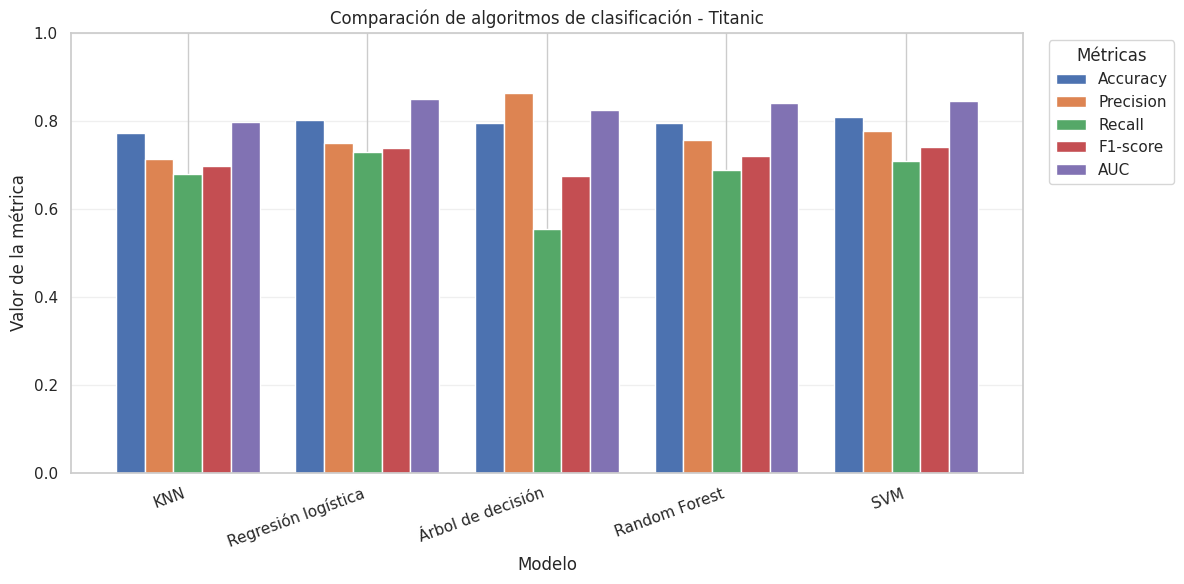

In [ ]:
resultados_grafica = resultados.set_index("Modelo")[
    ["Accuracy", "Precision", "Recall", "F1-score", "AUC"]
]

ax = resultados_grafica.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Comparación de algoritmos de clasificación - Titanic")
plt.xlabel("Modelo")
plt.ylabel("Valor de la métrica")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(title="Métricas", bbox_to_anchor=(1.02, 1))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### 8.3. Comparación mediante curvas ROC

Se representan las curvas ROC de los cinco modelos para comparar su capacidad de distinguir entre pasajeros sobrevivientes y no sobrevivientes.

El área bajo la curva (AUC) resume esta capacidad: cuanto más cercano a 1 sea su valor, mejor será la discriminación del modelo.

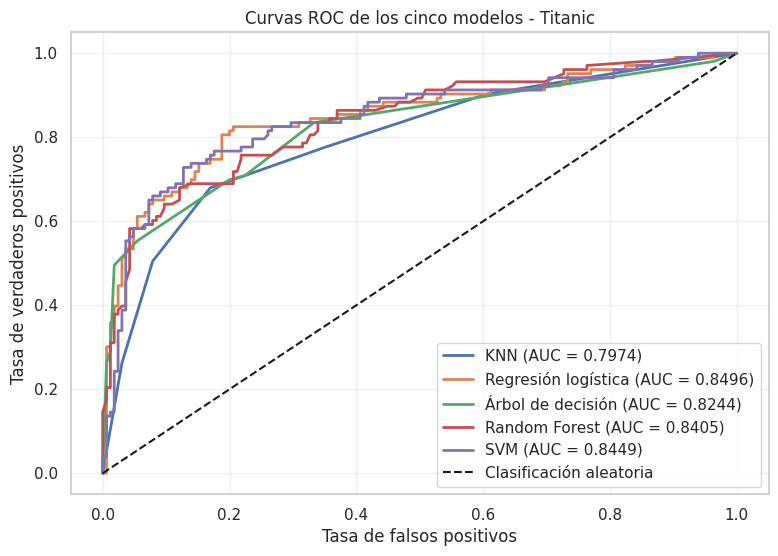

In [ ]:
from sklearn.metrics import roc_curve

modelos = {
    "KNN": modelo_knn,
    "Regresión logística": modelo_logistico,
    "Árbol de decisión": modelo_arbol,
    "Random Forest": modelo_rf,
    "SVM": modelo_svm
}

plt.figure(figsize=(9, 6))

for nombre, modelo in modelos.items():
    probabilidades = modelo.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, probabilidades)
    auc = roc_auc_score(y_test, probabilidades)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{nombre} (AUC = {auc:.4f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Clasificación aleatoria")

plt.title("Curvas ROC de los cinco modelos - Titanic")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

## 9. Análisis comparativo y conclusiones

### 9.1. Análisis comparativo

Se entrenaron y evaluaron cinco algoritmos de clasificación supervisada utilizando el conjunto de datos del Titanic: KNN, Regresión Logística, Árbol de Decisión, Random Forest y SVM.

Todos los modelos utilizaron el mismo conjunto de entrenamiento (623 registros) y prueba (268 registros), permitiendo comparar sus resultados bajo condiciones equivalentes.

El modelo **SVM obtuvo la mayor exactitud (80.97%) y el mejor F1-score (74.11%)**, mostrando el desempeño más favorable en estas métricas.

Por otra parte, la **Regresión Logística obtuvo el mayor AUC (84.96%) y Recall de sobrevivientes (72.82%)**, destacando por su capacidad de discriminación y detección de pasajeros que sobrevivieron.

El Árbol de Decisión presentó la mayor Precision de sobrevivientes (86.36%), aunque también registró el Recall más bajo (55.34%), lo que significa que dejó de identificar a una proporción considerable de sobrevivientes.

Random Forest obtuvo resultados más equilibrados que el árbol individual en la identificación de sobrevivientes, mientras que KNN presentó el menor Accuracy de los cinco modelos.

### 9.2. Selección del mejor modelo

Considerando conjuntamente Accuracy y F1-score, **SVM se selecciona como el modelo con mejor desempeño general en esta evaluación**.

Sin embargo, la Regresión Logística constituye una alternativa competitiva, especialmente cuando se busca identificar una mayor proporción de sobrevivientes o interpretar con mayor facilidad el funcionamiento del modelo.

La selección definitiva depende de las necesidades del problema y de la importancia asignada a los diferentes tipos de errores de clasificación.

### 9.3. Limitaciones del proyecto

Los resultados dependen de las características disponibles en el conjunto de datos y de la división utilizada para entrenamiento y prueba.

Algunas variables contienen valores faltantes que requieren imputación, lo que puede introducir incertidumbre.

Además, los algoritmos se evaluaron con configuraciones iniciales de hiperparámetros, sin realizar una búsqueda exhaustiva de las mejores combinaciones.

Por ello, los resultados obtenidos no garantizan que el mismo desempeño se mantenga con nuevos conjuntos de datos.

### 9.4. Posibles mejoras

- Aplicar validación cruzada para obtener estimaciones más estables del desempeño.
- Utilizar `GridSearchCV` o `RandomizedSearchCV` para optimizar los hiperparámetros.
- Incorporar nuevas características derivadas de los datos, como el tamaño de la familia o los títulos de los pasajeros.
- Analizar el impacto de diferentes estrategias de imputación y selección de variables.
- Evaluar el comportamiento de los modelos en otros conjuntos de datos.

### 9.5. Conclusión general

El proyecto permitió aplicar y comparar diferentes algoritmos de Machine Learning supervisado para predecir la supervivencia de pasajeros del Titanic.

Se comprobó que cada algoritmo presenta ventajas y limitaciones, y que la selección del mejor modelo no debe depender únicamente de la exactitud.

Los resultados muestran que **SVM y Regresión Logística fueron los modelos más competitivos** en esta práctica, mientras que los árboles de decisión y Random Forest permitieron explorar relaciones no lineales entre las características de los pasajeros.

En conclusión, la preparación de datos, la selección de variables y la evaluación mediante diferentes métricas son fundamentales para desarrollar modelos de clasificación confiables.

# 10. Recomendaciones técnicas

Se presentan las principales recomendaciones y los escenarios de aplicación más adecuados para cada uno de los cinco algoritmos de clasificación utilizados en el proyecto.

### 10.1. KNN (K-Nearest Neighbors)

**Recomendaciones:** Aplicar escalamiento mediante `StandardScaler`, probar diferentes valores de `n_neighbors` y utilizar validación cruzada.

**Escenario ideal:** Conjuntos de datos pequeños o medianos donde la similitud entre observaciones sea relevante.

### 10.2. Regresión logística

**Recomendaciones:** Ajustar la regularización, seleccionar variables significativas y evaluar posibles interacciones.

**Escenario ideal:** Problemas donde se requiere interpretar las variables y estimar probabilidades de supervivencia.

### 10.3. Árbol de decisión

**Recomendaciones:** Ajustar `max_depth`, `min_samples_split` y `min_samples_leaf` para controlar el sobreajuste.

**Escenario ideal:** Situaciones donde se necesitan reglas de decisión fáciles de interpretar y visualizar.

### 10.4. Random Forest

**Recomendaciones:** Optimizar `n_estimators`, `max_depth` y otros hiperparámetros mediante validación cruzada.

**Escenario ideal:** Problemas con múltiples características y relaciones no lineales entre las variables.

### 10.5. SVM (Support Vector Machine)

**Recomendaciones:** Mantener el escalamiento, ajustar los parámetros `C` y `gamma`, y comparar diferentes kernels.

**Escenario ideal:** Problemas de clasificación con fronteras de decisión complejas.

### Conclusión

Estas recomendaciones permitirían mejorar y evaluar la capacidad de generalización de los modelos, considerando tanto su precisión como sus necesidades de interpretación y procesamiento.

# 11. Reflexión final (Apoyo en IA)

A partir del análisis realizado con los cinco modelos de Machine Learning, se pueden identificar diferentes factores que influyeron en la supervivencia de los pasajeros del Titanic, así como las ventajas de utilizar inteligencia artificial para analizar este tipo de información.

### ¿Qué modelo funcionó mejor y por qué?

De acuerdo con los resultados obtenidos, **SVM fue el modelo con mejor desempeño general**, alcanzando una exactitud del **80.97 %** y un F1-score del **74.11 %** para los sobrevivientes.

Esto significa que logró un buen equilibrio al identificar a los pasajeros que sobrevivieron y a quienes no sobrevivieron.

Sin embargo, la **Regresión Logística también presentó resultados destacados**, especialmente al identificar sobrevivientes, por lo que ambos modelos pueden considerarse buenas alternativas dependiendo del objetivo del análisis.  


###¿Qué variables influyen más en la supervivencia?

Los resultados del análisis exploratorio y del árbol de decisión permiten identificar que **el sexo, la clase del pasajero y la edad** fueron características importantes relacionadas con la supervivencia.

Por ejemplo, las mujeres presentaron una mayor proporción de supervivencia que los hombres, mientras que los pasajeros de primera clase tuvieron mejores resultados que los de tercera clase.

También se observaron diferencias relacionadas con la edad, especialmente entre los pasajeros más pequeños.

Esto sugiere que las posibilidades de supervivencia no fueron iguales para todos los pasajeros, sino que estuvieron relacionadas con diferentes características personales y sociales.


###¿Qué patrones sociales se observan?

Uno de los patrones más evidentes es que **las mujeres y los pasajeros de primera clase tuvieron mayores posibilidades de sobrevivir**.

Desde una perspectiva social, estos resultados podrían estar relacionados con las prioridades de evacuación y las diferencias en las condiciones de viaje.

Por ejemplo, el porcentaje de supervivencia de las mujeres fue del **74.20 %**, mientras que el de los hombres fue del **18.89 %**.

De igual manera, los pasajeros de primera clase registraron una supervivencia del **62.96 %**, frente al **24.24 %** de los pasajeros de tercera clase.

Estos datos permiten observar cómo las diferencias sociales y las circunstancias de una emergencia pueden estar relacionadas con resultados muy distintos entre grupos de personas.


###¿Qué decisiones se podrían tomar con este análisis?

Aunque los acontecimientos del Titanic pertenecen al pasado, los resultados permiten comprender cómo la inteligencia artificial puede ayudar a identificar patrones y apoyar la toma de decisiones en situaciones de emergencia.

A partir de este análisis, sería posible proponer medidas como mejorar los protocolos de evacuación, garantizar que todos los pasajeros tengan acceso a las rutas de emergencia y prestar especial atención a las personas que necesitan asistencia.

También demuestra la importancia de utilizar información para detectar posibles desigualdades y diseñar estrategias de seguridad más equitativas.